# Homework 5

This file contains the solutions to the computational problems in Homework 5 from MATH 5750 taught by Braxton Osting during the Fall 2026 semester.

This code is a mix between my own work and code generated by ChatGPT.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def u_target(t, x):
    return (np.tanh(t * x / (1 - t)**2) - x) / (1 - t)

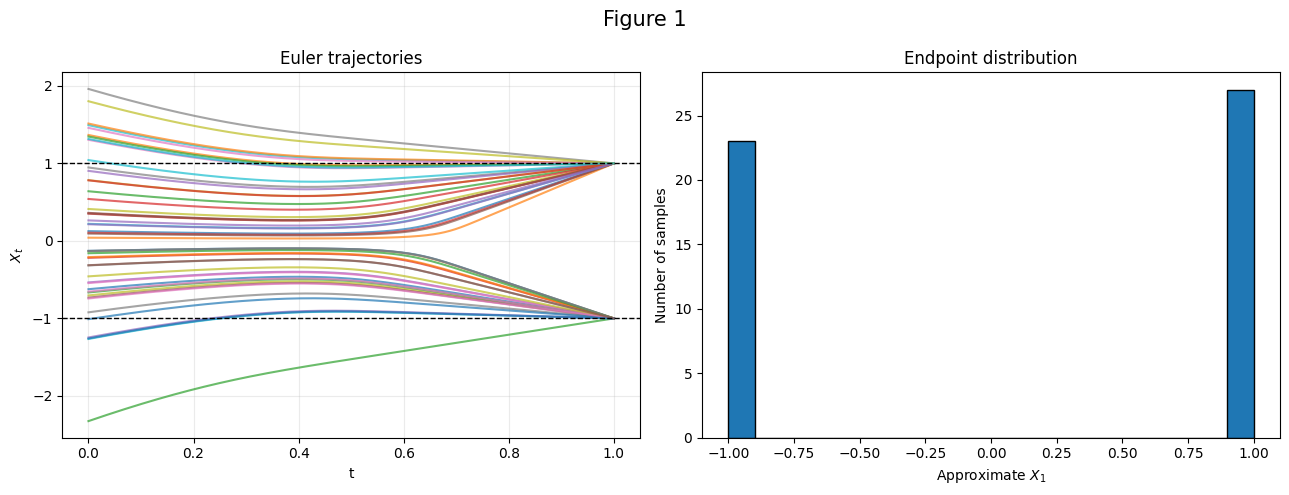

In [5]:
n = 1000
dt = 1 / n
num_samples = 50

t = np.arange(n) * dt

rng = np.random.default_rng(0)
X0 = rng.normal(0, 1, num_samples)

X = np.zeros((n + 1, num_samples))
X[0] = X0

# Euler method
for k in range(n):
    X[k + 1] = X[k] + dt * u_target(t[k], X[k])

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Left panel: trajectories
for j in range(num_samples):
    ax[0].plot(np.arange(n + 1) * dt, X[:, j], alpha=0.7)

ax[0].axhline(1, color="black", linestyle="--", linewidth=1)
ax[0].axhline(-1, color="black", linestyle="--", linewidth=1)
ax[0].set_xlabel("t")
ax[0].set_ylabel(r"$X_t$")
ax[0].set_title("Euler trajectories")
ax[0].grid(alpha=0.25)

# Right panel: endpoints near t = 1
ax[1].hist(X[-1], bins=20, edgecolor="black")
ax[1].set_xlabel(r"Approximate $X_1$")
ax[1].set_ylabel("Number of samples")
ax[1].set_title("Endpoint distribution")

fig.suptitle("Figure 1", fontsize=15)
plt.tight_layout()
plt.show()